# Roots of unity and grid cells (Fig. 2)

Reproduces Fig. 2 (Sec. 2.4, Appendices C and E): for the symmetry orders $M = 2, 3, 4$ and
$20$ on one ring, the eigenvalue ring, four plane waves $\alpha$, four units of the population
vector $p$ and the similarity $C$ relative to the origin. A population of 300 units follows,
with its rate maps and its similarity compared with the closed form of Eq. 4.

Metric preservation (App. E) requires the phasor sum $\sum_j e^{2i\phi_j}$ to vanish, and
evenly spaced angles $\phi_j = \pi j / M$ on the unit ring satisfy it for every $M \ge 2$. With
$M = 2$ the plane waves are $90^\circ$ apart and the units have square grid fields, with $M = 3$
they are $60^\circ$ apart and the fields are hexagonal, and as $M$ grows the similarity
approaches the radial $J_0$ profile of a single ring in the Fourier-Bessel series of
`bessel_zeros`.

In the canonical basis the representation is a direct product of planar rotations (App. C),

$$\alpha(x,y) = e^{x\Sigma_x + y\Sigma_y}\alpha_0,\qquad
  \alpha_i = \begin{pmatrix}\cos\Omega_i & -\sin\Omega_i\\ \sin\Omega_i & \cos\Omega_i\end{pmatrix}\alpha_{0,i},
  \qquad \Omega_i = x\lambda_{i,x} + y\lambda_{i,y},$$

so each pair of components is a plane wave. The population vector is the same object in the
neuron basis, $p = R^\top\alpha$.

The $20 \times 20$ arena is that of Appendix A. The mixing matrix $R$ and the position sampling
are the only random draws, and `SEED` fixes both. The ring, $\alpha$ and $C$ panels do not depend
on $R$. The example units $p$ in the paper were drawn with an unrecorded $R$, so the units here
match the paper in construction, not one by one.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.analysis import batch_inference, compute_ratemaps, compute_similarity
from expmap.generators import block_diag_skew, build_generators, roots_of_unity_eigenvalues
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import ExponentialMap
from expmap.plotting import ratemap_collage
from expmap.simulation import generate_uniform_positions

# Fig. 2: one ring of M roots per symmetry order, evaluated on a GRID_BINS x GRID_BINS grid.
M_VALUES = [2, 3, 4, 20]
ARENA_SIZE = 10.0  # 20 x 20 arena (Appendix A)
GRID_BINS = 64
SEED = 0

# The population: N_COPIES copies of the M = 3 ring, N = 2 * 3 * N_COPIES = 300 units,
# evaluated at random positions and binned into BINS x BINS rate maps.
N_COPIES = 50
BINS = 32
BATCH_SIZE, BATCHES = 50, 500

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

delta = np.linspace(-ARENA_SIZE, ARENA_SIZE, GRID_BINS)
DX, DY = np.meshgrid(delta, delta, indexing="ij")
positions = torch.tensor(np.stack([DX.ravel(), DY.ravel()], axis=1), dtype=torch.float32)
extent = (-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE)


def in_arena(maps):
    """Reorder (n, bins_x, bins_y) maps so that imshow draws x horizontal and y upward."""
    return maps.transpose(0, 2, 1)[:, ::-1]


# The four maps of a Fig. 2 collage, one root per column with its two phases stacked.
COLLAGE_ORDER = [0, 2, 1, 3]


def collage(maps, gutter=3):
    """The first four maps as one image, each scaled to [0, 1], separated by a transparent gutter."""
    maps = in_arena(maps)[COLLAGE_ORDER]
    n = maps.shape[1]
    tile = np.full((2 * n + gutter, 2 * n + gutter), np.nan)
    for k, m in enumerate(maps):
        r, c = divmod(k, 2)
        tile[r * (n + gutter) : r * (n + gutter) + n, c * (n + gutter) : c * (n + gutter) + n] = (m - m.min()) / (m.max() - m.min())
    return tile

## One ring per symmetry order

In [2]:
def build(M, n_copies=1, seed=SEED):
    """n_copies rings of M roots of unity at unit radius, mixed by a seeded R."""
    phi = roots_of_unity_eigenvalues(M, n_copies)
    sigma_x = block_diag_skew(np.cos(phi))
    sigma_y = block_diag_skew(np.sin(phi))

    R = random_orthogonal_matrix(2 * len(phi), seed=seed)
    p0 = starting_state(R)
    Gx, Gy = build_generators(sigma_x, sigma_y, R)
    return ExponentialMap(Gx, Gy), p0, R, phi


for M in M_VALUES:
    phi = roots_of_unity_eigenvalues(M)
    print(f"M = {M:2d}  |sum_j exp(2i phi_j)| = {np.abs(np.sum(np.exp(2j * phi))):.1e}")

M =  2  |sum_j exp(2i phi_j)| = 1.2e-16
M =  3  |sum_j exp(2i phi_j)| = 4.0e-16
M =  4  |sum_j exp(2i phi_j)| = 2.5e-16
M = 20  |sum_j exp(2i phi_j)| = 9.0e-16


In [3]:
results = {}

for M in M_VALUES:
    model, p0, R, phi = build(M)
    N = 2 * len(phi)

    with torch.no_grad():
        p = model(positions, p0).numpy()

    # The canonical basis, alpha = R p, where the origin state has uniform coefficients 1 / sqrt(N).
    alpha = (R.numpy() @ p.T).T
    alpha_0 = R.numpy() @ p0.numpy()

    ratemaps_p = p.T.reshape(N, GRID_BINS, GRID_BINS)
    ratemaps_alpha = alpha.T.reshape(N, GRID_BINS, GRID_BINS)
    similarity = compute_similarity(ratemaps_p, ref_bin=(GRID_BINS // 2, GRID_BINS // 2))

    results[M] = {
        "phi": phi, "N": N, "p": p, "alpha": alpha, "alpha_0": alpha_0,
        "ratemaps_p": ratemaps_p, "ratemaps_alpha": ratemaps_alpha, "similarity": similarity,
    }

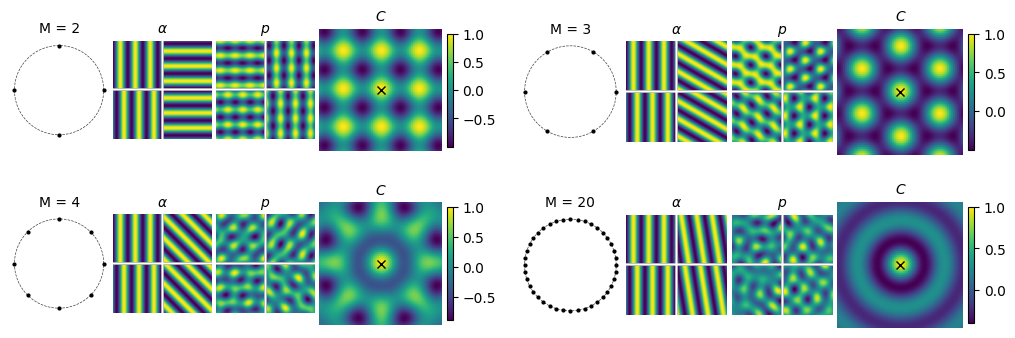

In [4]:
# Fig. 2 in the layout of the paper: for each M the ring, four plane waves, four units and C.
theta = np.linspace(0, 2 * np.pi, 200)
fig = plt.figure(figsize=(10, 3.4), layout="constrained")
fig.get_layout_engine().set(w_pad=0.02, h_pad=0.02, wspace=0.02, hspace=0.02)

for subfig, M in zip(fig.subfigures(2, 2, wspace=0.04, hspace=0.04).flat, M_VALUES):
    res = results[M]
    axs = subfig.subplots(1, 4, width_ratios=[1, 1, 1, 1.25])

    # The eigenvalue ring, each root with its conjugate.
    axs[0].plot(np.cos(theta), np.sin(theta), "k--", alpha=0.75, linewidth=0.5)
    conjugates = np.concatenate([res["phi"], res["phi"] + np.pi])
    axs[0].plot(np.cos(conjugates), np.sin(conjugates), "ko", markersize=2)
    axs[0].set_aspect("equal")
    axs[0].set_title(f"M = {M}", fontsize=10)

    axs[1].imshow(collage(res["ratemaps_alpha"]), cmap="viridis")
    axs[1].set_title(r"$\alpha$", fontsize=10)
    axs[2].imshow(collage(res["ratemaps_p"]), cmap="viridis")
    axs[2].set_title("$p$", fontsize=10)

    im = axs[3].imshow(res["similarity"].T, extent=extent, origin="lower", cmap="viridis", vmax=1)
    axs[3].plot(0, 0, "kx", markersize=6)
    axs[3].set_title("$C$", fontsize=10)
    subfig.colorbar(im, ax=axs[3], fraction=0.046, pad=0.04)
    for ax in axs:
        ax.axis("off")

fig.savefig(FIGURE_DIR / "RoU_figure2.svg", dpi=300, transparent=True, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "RoU_figure2.png", dpi=300, transparent=True, bbox_inches="tight")

In [5]:
# The same panels one file each, at the size they are assembled at in the paper.
for M in M_VALUES:
    res = results[M]

    plt.figure(figsize=(1, 1))
    plt.title(f"M = {M}")
    plt.plot(np.cos(theta), np.sin(theta), "k--", alpha=0.75, linewidth=0.5)
    conjugates = np.concatenate([res["phi"], res["phi"] + np.pi])
    plt.plot(np.cos(conjugates), np.sin(conjugates), "ko", markersize=1)
    plt.axis("equal")
    plt.axis("off")
    plt.savefig(FIGURE_DIR / f"RoU_roots_M={M}.svg", dpi=300, transparent=True, bbox_inches="tight")
    plt.close()

    for maps, suffix in [(res["ratemaps_alpha"], "alpha"), (res["ratemaps_p"], "p")]:
        fig, _ = ratemap_collage(in_arena(maps)[COLLAGE_ORDER], rows=2, cols=2, figsize=(1, 1))
        fig.savefig(FIGURE_DIR / f"RoU_M={M}_{suffix}.svg", dpi=300, transparent=True, bbox_inches="tight")
        plt.close(fig)

    plt.figure(figsize=(2, 2))
    plt.imshow(res["similarity"].T, extent=extent, origin="lower", vmax=1)
    plt.plot(0, 0, "kx", markersize=10)
    plt.colorbar(fraction=0.045)
    plt.axis("off")
    plt.savefig(FIGURE_DIR / f"RoU_M={M}_sim.svg", dpi=300, transparent=True, bbox_inches="tight")
    plt.close()

## A population of 300 units

The same construction with 50 copies of the $M = 3$ ring, the population size of the paper. The
rate maps are binned from random positions, as in the notebooks that use sampled trajectories.

In [6]:
M = 3
model, p0, R, phi = build(M, n_copies=N_COPIES)
Gx, Gy = model.Gx, model.Gy

# Commuting generators give path independence, skew-symmetric generators give equinorm.
assert torch.allclose(Gx @ Gy, Gy @ Gx, atol=1e-5), "generators must commute"
assert torch.allclose(Gx, -Gx.T, atol=1e-6), "generators must be skew-symmetric"
print(f"N = {len(Gx)} units")

N = 300 units


In [7]:
r_batch = generate_uniform_positions(BATCHES, BATCH_SIZE, ARENA_SIZE, seed=SEED)

p = batch_inference(model, r_batch, p0, progress=False)
r = np.concatenate(r_batch)

# The exponential of a skew-symmetric matrix is orthogonal, so every p has the norm of p0.
norms = np.linalg.norm(p, axis=1)
print(f"||p|| = {norms.mean():.6f} +/- {norms.std():.2e}")

||p|| = 0.999999 +/- 2.67e-06


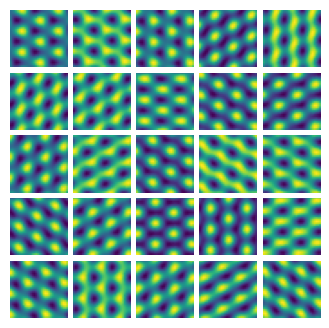

In [8]:
ratemaps = compute_ratemaps(r[:, 0], r[:, 1], p, bins=BINS)

fig, _ = ratemap_collage(in_arena(ratemaps), rows=5, cols=5, figsize=(4, 4))
fig.savefig(FIGURE_DIR / "RoU_ratemaps.svg", dpi=300, transparent=True)
fig.savefig(FIGURE_DIR / "RoU_ratemaps.png", dpi=300, transparent=True)

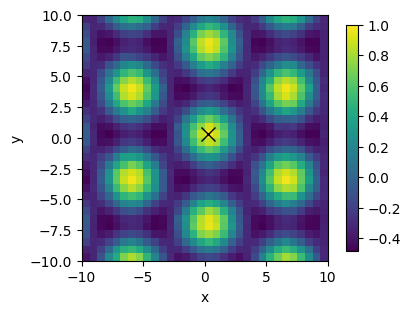

In [9]:
# All population vectors share a norm, so this dot product is the cosine similarity of Eq. 3.
a = BINS // 2
similarity = compute_similarity(ratemaps, ref_bin=(a, a))

edges = np.linspace(-ARENA_SIZE, ARENA_SIZE, BINS + 1)
centers = (edges[:-1] + edges[1:]) / 2

fig, ax = plt.subplots(figsize=(4, 4), layout="constrained")
im = ax.imshow(similarity.T, vmax=1, extent=extent, origin="lower")
ax.plot(centers[a], centers[a], "kx", markersize=10)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_xlabel("x")
ax.set_ylabel("y")
fig.savefig(FIGURE_DIR / "correlation.svg", dpi=300, transparent=True)
fig.savefig(FIGURE_DIR / "correlation.png", dpi=300, transparent=True)

## Checks against the closed form

Eq. 4 (App. F) gives the similarity in closed form. With the canonical
$\mathbf{p}_0 = R^\top \mathbf{1} / \sqrt{N}$ the coefficients are uniform, $\alpha_{0,i}^2 = 1/N$,
so $C(\Delta x, \Delta y) = \sum_i (2/N) \cos(\lambda_{i,x}\Delta x + \lambda_{i,y}\Delta y)$. It
depends on the displacement alone, not on $R$.

max |empirical - Eq. 4|        = 5.26e-06
max |binned rate maps - Eq. 4| = 7.86e-02


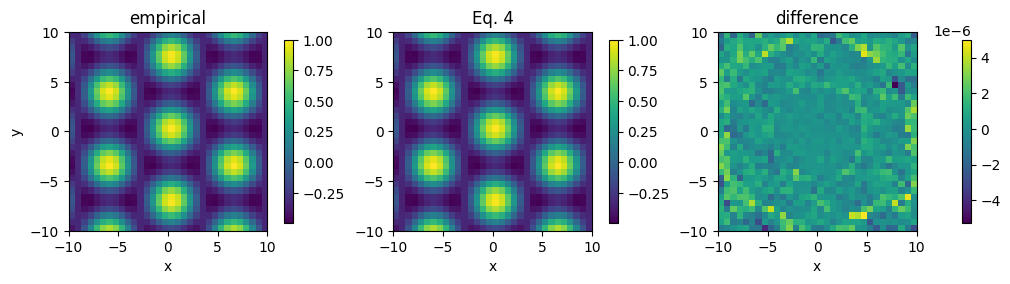

In [10]:
# Eq. 4 is compared at the bin centers. The binned rate maps above average about 24 random
# positions per 0.625-wide bin, and that averaging is their only difference from Eq. 4.
N = len(Gx)
X, Y = np.meshgrid(centers, centers, indexing="ij")
grid_positions = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32)
with torch.no_grad():
    p_grid = model(grid_positions, p0).numpy()

empirical = compute_similarity(p_grid.T.reshape(N, BINS, BINS), ref_bin=(a, a))

dx = centers[:, None] - centers[a]
dy = centers[None, :] - centers[a]
closed_form = sum((2 / N) * np.cos(np.cos(phi[i]) * dx + np.sin(phi[i]) * dy) for i in range(len(phi)))

print(f"max |empirical - Eq. 4|        = {np.nanmax(np.abs(empirical - closed_form)):.2e}")
print(f"max |binned rate maps - Eq. 4| = {np.nanmax(np.abs(similarity - closed_form)):.2e}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3.2), layout="constrained")
for ax, img, title in zip(
    axs,
    [empirical.T, closed_form.T, (empirical - closed_form).T],
    ["empirical", "Eq. 4", "difference"],
):
    im = ax.imshow(img, extent=extent, origin="lower")
    ax.set_title(title)
    ax.set_xlabel("x")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
axs[0].set_ylabel("y")
fig.savefig(FIGURE_DIR / "RoU_similarity_vs_closed_form.svg", dpi=300, transparent=True)